In [1]:
# ============================================================
# [CELL 1] MOUNT GOOGLE DRIVE
# ============================================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
# ============================================================
# [CELL 2] SETUP - Cai dat & kiem tra moi truong
# ============================================================
!pip install -q ultralytics
import ultralytics, torch, os
ultralytics.checks()
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHONG co GPU!")

Ultralytics 8.4.126 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.2/112.6 GB disk)
GPU: Tesla T4


In [3]:
# ============================================================
# [CELL 3] PATH - Khai bao 3 MODEL va 3 data.yaml (da xac nhan)
# ============================================================
import os

# --- Noi luu ket qua danh gia cheo (tren Drive, khong mat khi Colab reset) ---
PROJECT = "/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline"
NAME    = "cross_eval_3x3"

# --- 3 MODEL ---
MODELS = {
    "COCO-only":        "/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/YOLOv8n/baseline_100epochs_es/weights/best.pt",
    "CanTho fine-tune": "/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_cantho/weights/best.pt",
    "HCM fine-tune":    "/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_hcmc_701515/weights/best.pt",
}

# --- 3 data.yaml (tap test) ---
DATASETS = {
    "Test COCO":   "/content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicles-COCO_701515/data.yaml",
    "Test CanTho": "/content/drive/MyDrive/Do an AI giao thong/Dataset/CanTho_701515/data.yaml",
    "Test HCM":    "/content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/data.yaml",
}

# --- Kiem tra ton tai truoc khi chay ---
print("Kiem tra duong dan truoc khi chay:\n")
all_ok = True
for name, path in {**MODELS, **DATASETS}.items():
    status = "OK" if os.path.exists(path) else "KHONG THAY"
    if status == "KHONG THAY":
        all_ok = False
    print(f"[{status}] {name}: {path}")

if all_ok:
    print("\n=> Tat ca duong dan hop le, san sang chay danh gia cheo.")
else:
    print("\n=> CO duong dan bi thieu, sua lai truoc khi chay [CELL 4].")

Kiem tra duong dan truoc khi chay:

[OK] COCO-only: /content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/YOLOv8n/baseline_100epochs_es/weights/best.pt
[OK] CanTho fine-tune: /content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_cantho/weights/best.pt
[OK] HCM fine-tune: /content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_hcmc_701515/weights/best.pt
[OK] Test COCO: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicles-COCO_701515/data.yaml
[OK] Test CanTho: /content/drive/MyDrive/Do an AI giao thong/Dataset/CanTho_701515/data.yaml
[OK] Test HCM: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/data.yaml

=> Tat ca duong dan hop le, san sang chay danh gia cheo.


In [4]:
# ============================================================
# [CELL 4] CROSS-EVAL - Chay 3x3 = 9 phep danh gia (mAP@0.5 & mAP@0.5:0.95)
# ============================================================
from ultralytics import YOLO

model_list = list(MODELS.keys())
ds_list    = list(DATASETS.keys())

map50_matrix  = {}
map5095_matrix = {}

for model_name, model_path in MODELS.items():
    print(f"\n{'='*60}\nDANG LOAD MODEL: {model_name}\n{'='*60}")
    m = YOLO(model_path)
    for ds_name, ds_path in DATASETS.items():
        print(f"\n>>> Danh gia [{model_name}] tren [{ds_name}] ...")
        r = m.val(data=ds_path, split="test", imgsz=640,
                   project=PROJECT, name=f"{NAME}_{model_name}_{ds_name}".replace(" ", "_"),
                   exist_ok=True, verbose=False)
        map50_matrix[(model_name, ds_name)]   = float(r.box.map50)
        map5095_matrix[(model_name, ds_name)] = float(r.box.map)
        print(f"    mAP@0.5={r.box.map50:.4f}  |  mAP@0.5:0.95={r.box.map:.4f}")

print("\n\nHOAN TAT 9 PHEP DANH GIA.")


DANG LOAD MODEL: COCO-only

>>> Danh gia [COCO-only] tren [Test COCO] ...
Ultralytics 8.4.126 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.2 ms, read: 0.1±0.0 MB/s, size: 45.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicles-COCO_701515/test/labels... 2851 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2851/2851 2.6it/s 18:30
val: New cache created: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicles-COCO_701515/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 179/179 5.3it/s 34.0s
                   all       2851      10683      0.742      0.607      0.686       0.48
Speed: 1.3ms

In [5]:
# ============================================================
# [CELL 5] IN BANG KET QUA - mAP@0.5 va mAP@0.5:0.95
# ============================================================
def print_matrix(matrix, title):
    print(f"\n{'='*70}\n{title}\n{'='*70}")
    header = f"{'Model':20s}" + "".join(f"{d:>15s}" for d in ds_list)
    print(header)
    for mo in model_list:
        row = f"{mo:20s}"
        for ds in ds_list:
            val = matrix.get((mo, ds))
            row += f"{val:15.3f}" if val is not None else f"{'--':>15s}"
        print(row)

print_matrix(map50_matrix,   "MA TRAN mAP@0.5 (hang = model, cot = tap test)")
print_matrix(map5095_matrix, "MA TRAN mAP@0.5:0.95 (hang = model, cot = tap test)")

print("\nGhi chu:")
print(" - Duong cheo (COCO-only/TestCOCO, CanTho/TestCanTho, HCM/TestHCM) = ket qua 'san nha'.")
print(" - Ngoai duong cheo = do kha nang tong quat / muc do 'quen' (catastrophic forgetting).")


MA TRAN mAP@0.5 (hang = model, cot = tap test)
Model                     Test COCO    Test CanTho       Test HCM
COCO-only                     0.686          0.647          0.373
CanTho fine-tune              0.176          0.969          0.362
HCM fine-tune                 0.084          0.750          0.953

MA TRAN mAP@0.5:0.95 (hang = model, cot = tap test)
Model                     Test COCO    Test CanTho       Test HCM
COCO-only                     0.480          0.455          0.205
CanTho fine-tune              0.106          0.765          0.200
HCM fine-tune                 0.042          0.529          0.686

Ghi chu:
 - Duong cheo (COCO-only/TestCOCO, CanTho/TestCanTho, HCM/TestHCM) = ket qua 'san nha'.
 - Ngoai duong cheo = do kha nang tong quat / muc do 'quen' (catastrophic forgetting).


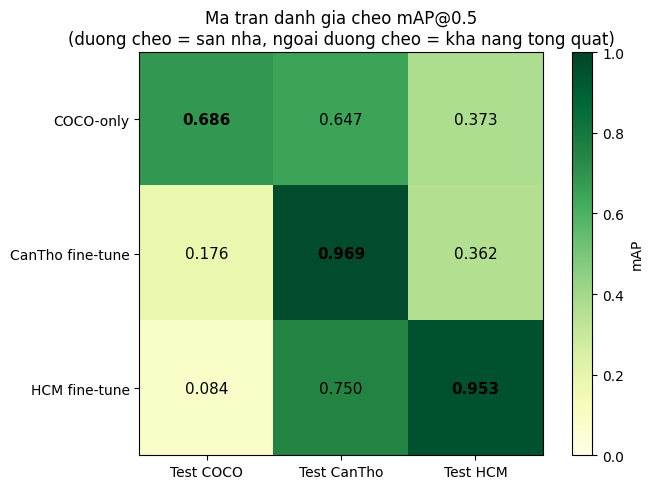

Da luu: /content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/cross_eval_3x3/cross_eval_map50_heatmap.png


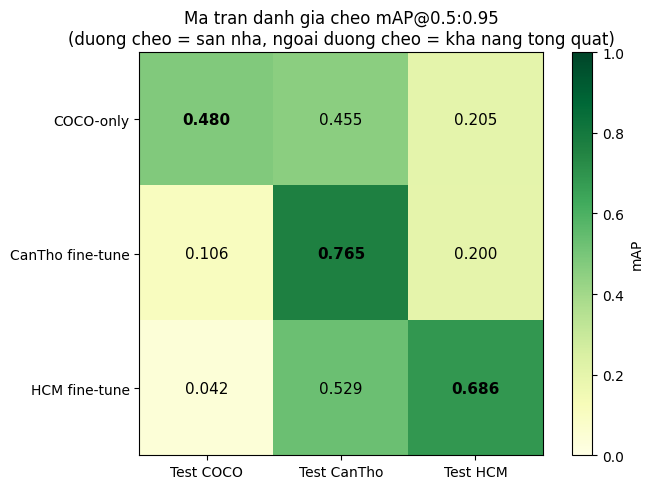

Da luu: /content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/cross_eval_3x3/cross_eval_map5095_heatmap.png


'/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/cross_eval_3x3/cross_eval_map5095_heatmap.png'

In [6]:
# ============================================================
# [CELL 6] VE HEATMAP - Truc quan hoa ma tran mAP@0.5
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

def plot_heatmap(matrix_dict, title, filename):
    matrix = np.full((len(model_list), len(ds_list)), np.nan)
    for i, mo in enumerate(model_list):
        for j, ds in enumerate(ds_list):
            v = matrix_dict.get((mo, ds))
            if v is not None:
                matrix[i, j] = v

    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(matrix, cmap="YlGn", vmin=0, vmax=1)

    ax.set_xticks(range(len(ds_list))); ax.set_xticklabels(ds_list)
    ax.set_yticks(range(len(model_list))); ax.set_yticklabels(model_list)
    ax.set_title(title)

    for i in range(len(model_list)):
        for j in range(len(ds_list)):
            if not np.isnan(matrix[i, j]):
                # highlight duong cheo (san nha)
                is_diag = (i == j)
                ax.text(j, i, f"{matrix[i,j]:.3f}", ha="center", va="center",
                        color="black", fontsize=11,
                        fontweight="bold" if is_diag else "normal")

    plt.colorbar(im, label="mAP")
    plt.tight_layout()
    out_path = os.path.join(PROJECT, NAME, filename)
    os.makedirs(os.path.join(PROJECT, NAME), exist_ok=True)
    plt.savefig(out_path, dpi=150)
    plt.show()
    print("Da luu:", out_path)
    return out_path

plot_heatmap(map50_matrix,
             "Ma tran danh gia cheo mAP@0.5\n(duong cheo = san nha, ngoai duong cheo = kha nang tong quat)",
             "cross_eval_map50_heatmap.png")

plot_heatmap(map5095_matrix,
             "Ma tran danh gia cheo mAP@0.5:0.95\n(duong cheo = san nha, ngoai duong cheo = kha nang tong quat)",
             "cross_eval_map5095_heatmap.png")

In [7]:
# ============================================================
# [CELL 7] PHAN TICH - Do muc do 'quen' (catastrophic forgetting)
# ============================================================
print("="*70)
print("PHAN TICH KHA NANG TONG QUAT & MUC DO QUEN (dua tren mAP@0.5)")
print("="*70)

# --- 1. CanTho fine-tune: con nho COCO khong? ---
sanha_cantho = map50_matrix.get(("CanTho fine-tune", "Test CanTho"))
quen_coco    = map50_matrix.get(("CanTho fine-tune", "Test COCO"))
if sanha_cantho and quen_coco is not None:
    print(f"\n[CanTho fine-tune]")
    print(f"  San nha (Test CanTho):     {sanha_cantho:.3f}")
    print(f"  Con nho COCO (Test COCO):  {quen_coco:.3f}  (chenh lech: {quen_coco - sanha_cantho:+.3f})")

# --- 2. HCM fine-tune: con nho CanTho va COCO khong? ---
sanha_hcm     = map50_matrix.get(("HCM fine-tune", "Test HCM"))
quen_cantho   = map50_matrix.get(("HCM fine-tune", "Test CanTho"))
quen_coco_hcm = map50_matrix.get(("HCM fine-tune", "Test COCO"))
if sanha_hcm is not None:
    print(f"\n[HCM fine-tune]")
    print(f"  San nha (Test HCM):        {sanha_hcm:.3f}")
    if quen_cantho is not None:
        print(f"  Con nho CanTho (Test CanTho): {quen_cantho:.3f}  (chenh lech: {quen_cantho - sanha_hcm:+.3f})")
    if quen_coco_hcm is not None:
        print(f"  Con nho COCO (Test COCO):     {quen_coco_hcm:.3f}  (chenh lech: {quen_coco_hcm - sanha_hcm:+.3f})")

# --- 3. Kha nang tong quat cua CanTho-model sang HCM (truoc khi fine-tune them) ---
tongquat_cantho_to_hcm = map50_matrix.get(("CanTho fine-tune", "Test HCM"))
if tongquat_cantho_to_hcm is not None and sanha_hcm is not None:
    print(f"\n[Gia tri gia tang cua buoc fine-tune HCM]")
    print(f"  CanTho-model tren Test HCM (chua fine-tune them): {tongquat_cantho_to_hcm:.3f}")
    print(f"  HCM-model tren Test HCM (da fine-tune):           {sanha_hcm:.3f}")
    print(f"  => Cai thien nho fine-tune them HCM: {sanha_hcm - tongquat_cantho_to_hcm:+.3f}")

print("\n" + "="*70)
print("Ket luan mau (dieu chinh lai theo so lieu thuc te sau khi chay):")
print("- Neu chenh lech duong cheo vs ngoai duong cheo LON -> model bi 'quen' manh")
print("  domain cu sau khi fine-tune tiep -> can can nhac them du lieu 'on lai' (rehearsal).")
print("- Neu CanTho-model van dat mAP kha tren Test HCM -> CanTho da tong quat tot,")
print("  buoc fine-tune them HCM mang lai cai thien nhung khong qua dot pha.")
print("="*70)

PHAN TICH KHA NANG TONG QUAT & MUC DO QUEN (dua tren mAP@0.5)

[CanTho fine-tune]
  San nha (Test CanTho):     0.969
  Con nho COCO (Test COCO):  0.176  (chenh lech: -0.793)

[HCM fine-tune]
  San nha (Test HCM):        0.953
  Con nho CanTho (Test CanTho): 0.750  (chenh lech: -0.203)
  Con nho COCO (Test COCO):     0.084  (chenh lech: -0.869)

[Gia tri gia tang cua buoc fine-tune HCM]
  CanTho-model tren Test HCM (chua fine-tune them): 0.362
  HCM-model tren Test HCM (da fine-tune):           0.953
  => Cai thien nho fine-tune them HCM: +0.591

Ket luan mau (dieu chinh lai theo so lieu thuc te sau khi chay):
- Neu chenh lech duong cheo vs ngoai duong cheo LON -> model bi 'quen' manh
  domain cu sau khi fine-tune tiep -> can can nhac them du lieu 'on lai' (rehearsal).
- Neu CanTho-model van dat mAP kha tren Test HCM -> CanTho da tong quat tot,
  buoc fine-tune them HCM mang lai cai thien nhung khong qua dot pha.
